In [1]:
import torch, copy
from pathlib import Path
import matplotlib.pyplot as plt

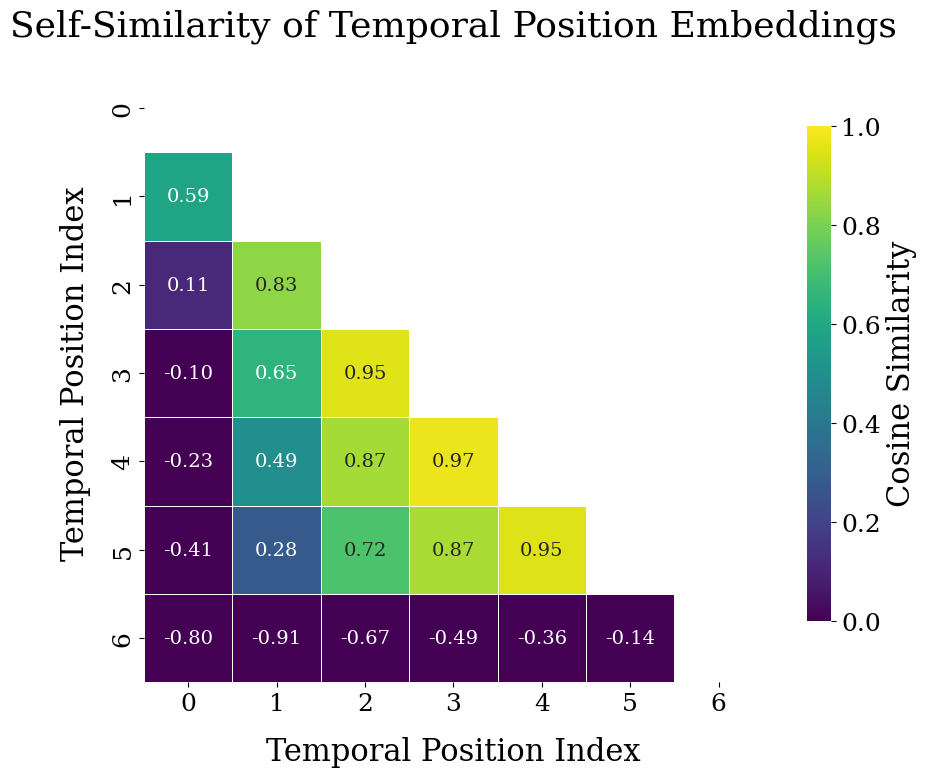

In [5]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

# --- 1. GLOBAL SETTINGS: BIGGER FONTS (Restored "As Before") ---
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 14,              # General text
    'axes.titlesize': 26,         # Plot titles
    'axes.labelsize': 22,         # Axis labels (x and y)
    'xtick.labelsize': 18,        # X-tick labels
    'ytick.labelsize': 18,        # Y-tick numbers
    'legend.fontsize': 18,        # Legend text
    'figure.titlesize': 30        # Super title
})

# --- 2. LOAD & PROCESS DATA ---
ckpt_path = Path("../src/base_sam2/sam2/checkpoints/sam2.1_hiera_small.pt")
# assert ckpt_path.exists(), f"Checkpoint not found at {ckpt_path}"

# Load checkpoint
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
sd = ckpt["model"]

# Extract embeddings (Shape: 7x64)
embeddings = sd["maskmem_tpos_enc"].reshape(7, 64).float()
memory_tpos_enc_array = embeddings.detach().numpy()
# Normalize to unit length (so dot product = cosine similarity)
embeddings_norm = F.normalize(embeddings, p=2, dim=1)

# Compute Cosine Similarity Matrix (7x7)
similarity_matrix = torch.mm(embeddings_norm, embeddings_norm.t()).detach().numpy()

# Create mask for upper triangle (to show only lower half)
mask = np.triu(np.ones_like(similarity_matrix, dtype=bool))

# --- 3. PLOTTING ---
# Increased figure size to accommodate larger fonts without crowding
fig, ax = plt.subplots(figsize=(10, 8))

# Draw Heatmap
sns.heatmap(similarity_matrix, 
            mask=mask, 
            annot=True, 
            fmt=".2f", 
            cmap="viridis", 
            square=True, 
            linewidths=0.5, 
            ax=ax,
            vmin=0, vmax=1,
            annot_kws={"size": 14}, # Increased annotation size inside cells
            cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"})

# --- 4. FORMATTING ---
# We remove the explicit fontsize arguments so the global rcParams take effect
ax.set_title('Self-Similarity of Temporal Position Embeddings', pad=20)
ax.set_xlabel('Temporal Position Index', labelpad=15)
ax.set_ylabel('Temporal Position Index', labelpad=15)

# Ensure layout is tight and clean
plt.tight_layout()
plt.show()

In [3]:
interpolated_copy_idxs =[0,1,2,3,4,5,6,6,6,6,6,6,6]
print(len(interpolated_copy_idxs))
memory_tpos_enc_interp_array = memory_tpos_enc_array[interpolated_copy_idxs]
# convert back to torch and shape torch.Size([7, 1, 1, 64])
memory_tpos_enc_interp = torch.from_numpy(memory_tpos_enc_interp_array)
memory_tpos_enc_interp = memory_tpos_enc_interp.reshape(13,1,1,64)

# save to /home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/doubled_to_12.pt

torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_interp}}, "/home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/doubled_to_12.pt")

13


NameError: name 'memory_tpos_enc_array' is not defined

In [6]:
zeros_memory_tpos_enc = torch.zeros(6,64)
# join zeros_memory_tpos_enc and the original memory_tpos_enc
memory_tpos_enc_interp = torch.cat([zeros_memory_tpos_enc, memory_tpos_enc], dim=0)
# save to /home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/doubled_to_12.pt
memory_tpos_enc_interp = memory_tpos_enc_interp.reshape(13,1,1,64)

torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_interp}}, "/home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/doubled_to_12_zeroed.pt")


RuntimeError: Parent directory /home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory does not exist.

In [84]:
# slice memory_tpos_enc to have only 0:3
memory_tpos_enc_slice = memory_tpos_enc_array[0:3]
memory_tpos_enc_slice = torch.from_numpy(memory_tpos_enc_slice)
memory_tpos_enc_slice = memory_tpos_enc_slice.reshape(3,1,1,64)
torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_slice}}, "/home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/sliced_to_3.pt")


In [85]:
# slice memory_tpos_enc to have only 0:3
memory_tpos_enc_slice = memory_tpos_enc_array[0:4]
memory_tpos_enc_slice = torch.from_numpy(memory_tpos_enc_slice)
memory_tpos_enc_slice = memory_tpos_enc_slice.reshape(4,1,1,64)
torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_slice}}, "/home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/sliced_to_4.pt")


# 0 to 6 slices

In [ ]:
# mkdir
directory = "../src/base_sam2/sam2/checkpoints/memory/"
Path(directory).mkdir(parents=True, exist_ok=True)
for i in range(7):
    # slice 0:
    print(i)
    memory_tpos_enc_slice = memory_tpos_enc_array[0:i+1]
    memory_tpos_enc_slice = torch.from_numpy(memory_tpos_enc_slice)
    memory_tpos_enc_slice = memory_tpos_enc_slice.reshape(i+1,1,1,64)
    torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_slice}}, f"../src/base_sam2/sam2/checkpoints/memory/sliced_to_{i}.pt")
    


0
1
2
3
4
5
6


we noww make it by always keeping the 0, 1 and 6th slice and varying the middle slices so we have 0,1,6 ; 0,1,2,6 ; 0,1,2,3,6 ; 0,1,2,3,4,6 ; 0,1,2,3,4,5,6

In [11]:
for i in range(1,7):
    idxs = [0,1] + list(range(2,i+1)) + [6]
    sliced_memory = memory_tpos_enc_array[idxs]
    sliced_memory = torch.from_numpy(sliced_memory)
    sliced_memory = sliced_memory.reshape(len(idxs),1,1,64)
    print(f"saving sliced_special_to_{i}.pt with shape {sliced_memory.shape}")
    torch.save({"model": {"maskmem_tpos_enc": sliced_memory}}, f"../src/base_sam2/sam2/checkpoints/memory/sliced_special_to_{i}.pt")

saving sliced_special_to_1.pt with shape torch.Size([3, 1, 1, 64])
saving sliced_special_to_2.pt with shape torch.Size([4, 1, 1, 64])
saving sliced_special_to_3.pt with shape torch.Size([5, 1, 1, 64])
saving sliced_special_to_4.pt with shape torch.Size([6, 1, 1, 64])
saving sliced_special_to_5.pt with shape torch.Size([7, 1, 1, 64])
saving sliced_special_to_6.pt with shape torch.Size([8, 1, 1, 64])


we now try making it longer by repeating the last but one slice

In [6]:
idxs = {
    'sliced_1':  [0,1,6],
    'sliced_2':  [0,1,5,6],
    'sliced_3':  [0,1,4,5,6],
    'sliced_4':  [0,1,3,4,5,6],
}
for name, id_list in idxs.items():
    sliced_memory = memory_tpos_enc_array[id_list]
    sliced_memory = torch.from_numpy(sliced_memory)
    sliced_memory = sliced_memory.reshape(len(id_list),1,1,64)
    print(f"saving {name}.pt with shape {sliced_memory.shape}")
    torch.save({"model": {"maskmem_tpos_enc": sliced_memory}}, f"../src/base_sam2/sam2/checkpoints/memory/{name}.pt")

saving sliced_1.pt with shape torch.Size([3, 1, 1, 64])
saving sliced_2.pt with shape torch.Size([4, 1, 1, 64])
saving sliced_3.pt with shape torch.Size([5, 1, 1, 64])
saving sliced_4.pt with shape torch.Size([6, 1, 1, 64])


In [20]:
# compare
original_weights = sd["maskmem_tpos_enc"]
# with emory_tpos_enc_array[0:6]
memory_tpos_enc_array_6 = memory_tpos_enc_array[0:6+1]
memory_tpos_enc_array_6 = torch.from_numpy(memory_tpos_enc_array_6)
memory_tpos_enc_array_6 = memory_tpos_enc_array_6.reshape(7,1,1,64)

# compare the shapes
print(original_weights.shape)
print(memory_tpos_enc_array_6.shape)

# compare the values
assert torch.allclose(original_weights, memory_tpos_enc_array_6)



torch.Size([7, 1, 1, 64])
torch.Size([7, 1, 1, 64])


# Repetitions

In [ ]:
weight_extensions = {
    "repeat_end_1": [0,1,2,3,4,5,6,6],
    "repeat_end_2": [0,1,2,3,4,5,6,6,6],
    "repeat_end_3": [0,1,2,3,4,5,6,6,6,6],
}
for key, idxs in weight_extensions.items():
    memory_tpos_enc_interp_array = memory_tpos_enc_array[idxs]
    memory_tpos_enc_interp = torch.from_numpy(memory_tpos_enc_interp_array)
    memory_tpos_enc_interp = memory_tpos_enc_interp.reshape(len(idxs),1,1,64)
    torch.save({"model": {"maskmem_tpos_enc": memory_tpos_enc_interp}}, f"/home/sam2group/Sam2/ML-P2-Sam2/src/base_sam2/sam2/checkpoints/memory/{key}.pt")
